# Projet : Rossmann Store Sales
Projet de prévision des ventes (variable cible : Sales), réparti en 5 tâches, du nettoyage à l’évaluation finale.

### Tâche 1 : initialisation du dépôt

In [20]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

os.makedirs("data", exist_ok=True)
os.makedirs("reports", exist_ok=True)

### Tâche 2 : structure du dataset

In [21]:
df = pd.read_csv("data/rossmann_stores_sales.csv")
sales_brut = df["Sales"].copy()   # gardée pour la comparaison avant/après

print("Taille :", df.shape)
print("\nTypes :\n", df.dtypes)
print("\nManquants :\n", df.isna().sum())
print("\nDoublons exacts :", df.duplicated().sum())
print("Doublons Store+Date :", df.duplicated(["Store", "Date"]).sum())
print("Période :", df["Date"].min(), "->", df["Date"].max())
print("Magasins :", df["Store"].nunique())

for c in ["StoreType", "Assortment", "StateHoliday", "PromoInterval"]:
    print(f"\n{c} :", df[c].map(repr).value_counts(dropna=False).to_dict())

print("\nSales négatives :", (df["Sales"] < 0).sum())
df["Sales"].describe()

Taille : (810056, 16)

Types :
 Store                          int64
Date                             str
DayOfWeek                      int64
Sales                        float64
Promo                          int64
StateHoliday                     str
SchoolHoliday                  int64
StoreType                        str
Assortment                       str
CompetitionDistance          float64
CompetitionOpenSinceMonth    float64
CompetitionOpenSinceYear     float64
Promo2                         int64
Promo2SinceWeek              float64
Promo2SinceYear              float64
PromoInterval                    str
dtype: object

Manquants :
 Store                             0
Date                              0
DayOfWeek                         0
Sales                           814
Promo                             0
StateHoliday                   8099
SchoolHoliday                     0
StoreType                         0
Assortment                        0
CompetitionDistance     

count    809242.000000
mean       6157.516553
std        3141.648269
min      -18554.000000
25%        4501.000000
50%        6321.000000
75%        8137.000000
max       21387.000000
Name: Sales, dtype: float64

### Tâche 3 : doublons, types, écriture des catégories

In [22]:
# Doublons
n0 = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print(f"Doublons supprimés : {n0 - len(df)} ({n0} -> {len(df)})")

# Date
df["Date"] = pd.to_datetime(df["Date"], format="%Y-%m-%d")

# Écriture des catégories
for c in ["StoreType", "Assortment"]:
    propre = df[c].str.strip().str.lower()
    print(f"{c} : {(df[c] != propre).sum()} lignes modifiées")
    df[c] = propre.astype("category")
    print("  modalités :", list(df[c].cat.categories))

Doublons supprimés : 6000 (810056 -> 804056)
StoreType : 63696 lignes modifiées
  modalités : ['a', 'b', 'c', 'd']
Assortment : 64591 lignes modifiées
  modalités : ['a', 'b', 'c']


### Tâche 4 : cohérence des valeurs et outliers

In [23]:
# Date / DayOfWeek (lundi = 1 ... dimanche = 7)
print("DayOfWeek incohérents :", ((df["Date"].dt.day_of_week + 1) != df["DayOfWeek"]).sum())

# Sales négatives : preuve de l'erreur de signe, puis correction
neg = df["Sales"] < 0
pos = df.loc[df["Sales"] > 0, "Sales"]
print("\nSales négatives (après doublons) :", neg.sum())
print("|négatives| :", df.loc[neg, "Sales"].abs().describe()[["min", "50%", "mean"]].to_dict())
print("positives   :", pos.describe()[["min", "50%", "mean"]].to_dict())
df.loc[neg, "Sales"] = df.loc[neg, "Sales"].abs()

# Ventes à 0
zeros = df[df["Sales"] == 0]
print("\nSales = 0 :", len(zeros), "| jours de la semaine :", zeros["DayOfWeek"].value_counts().to_dict())

# Outliers Sales (IQR sur Sales > 0) : conservés, signalés
pos = df.loc[df["Sales"] > 0, "Sales"]
q1, q3 = pos.quantile([0.25, 0.75])
borne = q3 + 1.5 * (q3 - q1)
print(f"Outliers Sales > {borne:.0f} :", (pos > borne).sum(), "| max :", df["Sales"].max())

# Outliers CompetitionDistance (niveau magasin)
cd = df.groupby("Store")["CompetitionDistance"].first().dropna()
a, b = cd.quantile([0.25, 0.75])
out = ((cd < a - 1.5 * (b - a)) | (cd > b + 1.5 * (b - a))).sum()
print("\nCompetitionDistance : min", round(cd.min(), 2), "max", round(cd.max(), 2), "| outliers IQR :", out)

# StateHoliday : dates portant a / b / c
sh = df.dropna(subset=["StateHoliday"])
for v in ["a", "b", "c"]:
    print(f"StateHoliday = {v} : {sh.loc[sh['StateHoliday'] == v, 'Date'].nunique()} dates distinctes")

DayOfWeek incohérents : 0

Sales négatives (après doublons) : 2860
|négatives| : {'min': 2576.0, '50%': 6660.5, 'mean': 6784.492307692308}
positives   : {'min': 2574.0, '50%': 6689.0, 'mean': 6894.073729314831}

Sales = 0 : 80190 | jours de la semaine : {7: 80190}
Outliers Sales > 13259 : 6358 | max : 21387.0

CompetitionDistance : min 27.6 max 74973.32 | outliers IQR : 0
StateHoliday = a : 718 dates distinctes
StateHoliday = b : 718 dates distinctes
StateHoliday = c : 1 dates distinctes


### Tâche 5 : valeurs manquantes

In [24]:
# 1. Sales : cible manquante -> suppression
n = df["Sales"].isna().sum()
df = df.dropna(subset=["Sales"]).reset_index(drop=True)
df["Sales"] = df["Sales"].astype("int64")
print(f"Sales manquantes supprimées : {n} -> {len(df)} lignes")

# 2. StateHoliday : valeur majoritaire du même jour
df["StateHoliday"] = df["StateHoliday"].astype("string")
mode_jour = df.groupby("Date")["StateHoliday"].agg(lambda s: s.dropna().mode().iloc[0])
manq = df["StateHoliday"].isna()
print(f"StateHoliday manquants : {manq.sum()} dont 'c' : {(manq & (df['Date'].map(mode_jour) == 'c')).sum()}")
df["StateHoliday"] = df["StateHoliday"].fillna(df["Date"].map(mode_jour))

# 3. CompetitionDistance : valeur du même magasin, sinon médiane des magasins
avant = df["CompetitionDistance"].isna().sum()
df["CompetitionDistance"] = df.groupby("Store")["CompetitionDistance"].transform(lambda s: s.ffill().bfill())
reste = df["CompetitionDistance"].isna().sum()
mediane = df.groupby("Store")["CompetitionDistance"].first().median()
print(f"CompetitionDistance : {avant} manquants, {avant - reste} récupérés via le magasin, "
      f"{reste} remplis par la médiane ({mediane:.2f}) pour {df.loc[df['CompetitionDistance'].isna(), 'Store'].nunique()} magasins")
df["CompetitionDistance"] = df["CompetitionDistance"].fillna(mediane)

# 4. CompetitionOpenSince* : 0 = inconnu / sans objet
print("CompetitionOpenSince* manquants :", df["CompetitionOpenSinceMonth"].isna().sum(),
      "| magasins :", df.loc[df["CompetitionOpenSinceMonth"].isna(), "Store"].nunique())
for c in ["CompetitionOpenSinceMonth", "CompetitionOpenSinceYear"]:
    df[c] = df[c].fillna(0).astype("int64")

# 5. Promo2 : vide exactement quand Promo2 = 0 -> 0 / "Aucun"
cols = ["Promo2SinceWeek", "Promo2SinceYear", "PromoInterval"]
incoh = ((df["Promo2"] == 0) & df[cols].notna().any(axis=1)).sum() + ((df["Promo2"] == 1) & df[cols].isna().any(axis=1)).sum()
print("Promo2 : lignes à 0 =", (df["Promo2"] == 0).sum(), "| incohérences :", incoh)
for c in ["Promo2SinceWeek", "Promo2SinceYear"]:
    df[c] = df[c].fillna(0).astype("int64")
df["PromoInterval"] = df["PromoInterval"].fillna("Aucun")

# 6. Types finaux
for c in ["StateHoliday", "PromoInterval"]:
    df[c] = df[c].astype("category")
for c in ["Store", "DayOfWeek", "Promo", "SchoolHoliday", "Promo2"]:
    df[c] = df[c].astype("int64")

assert df.isna().sum().sum() == 0 and not df.duplicated().any()
print("\nFinal :", df.shape, "| manquants : 0 | doublons : 0")
df.dtypes

Sales manquantes supprimées : 804 -> 803252 lignes
StateHoliday manquants : 7237 dont 'c' : 11
CompetitionDistance : 52767 manquants, 14594 récupérés via le magasin, 38173 remplis par la médiane (37583.38) pour 53 magasins
CompetitionOpenSince* manquants : 117412 | magasins : 163
Promo2 : lignes à 0 = 505696 | incohérences : 0

Final : (803252, 16) | manquants : 0 | doublons : 0


Store                                 int64
Date                         datetime64[us]
DayOfWeek                             int64
Sales                                 int64
Promo                                 int64
StateHoliday                       category
SchoolHoliday                         int64
StoreType                          category
Assortment                         category
CompetitionDistance                 float64
CompetitionOpenSinceMonth             int64
CompetitionOpenSinceYear              int64
Promo2                                int64
Promo2SinceWeek                       int64
Promo2SinceYear                       int64
PromoInterval                      category
dtype: object

### Tâche 6 : export de data_clean.csv et comparaison avant/après

,avant,apres
n,809242.0,803252.0
moyenne,6157.5,6205.4
ecart_type,3141.6,3045.4
min,-18554.0,0.0
Q1,4501.0,4524.0
mediane,6321.0,6334.0
Q3,8137.0,8144.0
max,21387.0,21387.0
negatives,2875.0,0.0
zeros,80767.0,80190.0


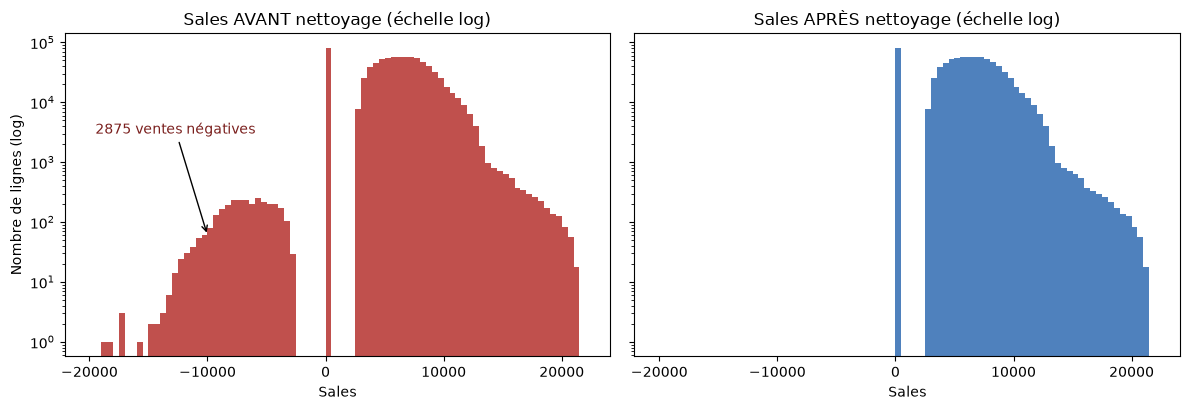

data_clean.csv : (803252, 16)


In [25]:
avant = sales_brut.dropna()
apres = df["Sales"]

def resume(s):
    return {"n": s.count(), "moyenne": round(s.mean(), 1), "ecart_type": round(s.std(), 1),
            "min": s.min(), "Q1": s.quantile(.25), "mediane": s.median(), "Q3": s.quantile(.75),
            "max": s.max(), "negatives": int((s < 0).sum()), "zeros": int((s == 0).sum())}

tab = pd.DataFrame({"avant": resume(avant), "apres": resume(apres)})
tab.to_csv("reports/sales_avant_apres.csv")
display(tab)

fig, ax = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
bins = np.linspace(-20000, 22000, 85)
ax[0].hist(avant, bins=bins, color="#c0504d", log=True)
ax[0].set_title("Sales AVANT nettoyage (échelle log)")
ax[1].hist(apres, bins=bins, color="#4f81bd", log=True)
ax[1].set_title("Sales APRÈS nettoyage (échelle log)")
ax[0].annotate(f"{(avant < 0).sum()} ventes négatives", xy=(-10000, 60), xytext=(-19500, 3000),
               arrowprops=dict(arrowstyle="->"), color="#7a1f1d")
for a in ax:
    a.set_xlabel("Sales")
ax[0].set_ylabel("Nombre de lignes (log)")
plt.tight_layout()
plt.savefig("reports/sales_avant_apres.png", dpi=130)
plt.show()

df.to_csv("data/clean/data_clean.csv", index=False, date_format="%Y-%m-%d")
print("data_clean.csv :", df.shape)

### Tâche 7 : dictionnaire des données

In [26]:
definitions = {
    "Store": "Identifiant du magasin",
    "Date": "Jour de la vente",
    "DayOfWeek": "Jour de la semaine (1 = lundi, 7 = dimanche)",
    "Sales": "Chiffre d'affaires du jour (variable cible) ; 0 = aucune vente",
    "Promo": "Promotion ponctuelle ce jour-là (0 = non, 1 = oui)",
    "StateHoliday": "Jour férié légal (0 = aucun, a = jour férié, b = Pâques, c = Noël)",
    "SchoolHoliday": "Vacances scolaires (0 = non, 1 = oui)",
    "StoreType": "Modèle de magasin (signification détaillée non fournie)",
    "Assortment": "Niveau d'assortiment (a = basique, b = supplémentaire, c = étendu)",
    "CompetitionDistance": "Distance au concurrent le plus proche, en mètres",
    "CompetitionOpenSinceMonth": "Mois d'ouverture du concurrent (0 = inconnu)",
    "CompetitionOpenSinceYear": "Année d'ouverture du concurrent (0 = inconnu)",
    "Promo2": "Participation à la promotion continue Promo2 (0 = non, 1 = oui)",
    "Promo2SinceWeek": "Semaine de début de Promo2 (0 = sans objet)",
    "Promo2SinceYear": "Année de début de Promo2 (0 = sans objet)",
    "PromoInterval": "Mois de relance de Promo2 (Aucun = sans objet)",
}

def valeurs_possibles(s):
    if isinstance(s.dtype, pd.CategoricalDtype):
        return " | ".join(map(str, s.cat.categories))
    if pd.api.types.is_datetime64_any_dtype(s):
        return f"{s.min().date()} à {s.max().date()}"
    if s.nunique() <= 10:
        return ", ".join(str(round(v, 2)) for v in sorted(s.unique()))
    if (s == 0).any():
        return f"0 ; {round(s[s > 0].min(), 2)} à {round(s.max(), 2)}"
    return f"{round(s.min(), 2)} à {round(s.max(), 2)}"

dico = pd.DataFrame({
    "Colonne": df.columns,
    "Type": [str(t) for t in df.dtypes],
    "Valeurs distinctes": [df[c].nunique() for c in df.columns],
    "Valeurs possibles": [valeurs_possibles(df[c]) for c in df.columns],
    "Manquants": df.isna().sum().values,
    "Définition": [definitions[c] for c in df.columns],
})
dico.to_csv("reports/dictionnaire_donnees.csv", index=False, encoding="utf-8-sig")
dico

,Colonne,Type,Valeurs distinctes,Valeurs possibles,Manquants,Définition
0,Store,int64,1115,1 à 1115,0,Identifiant du magasin
1,Date,datetime64[us],722,2013-01-01 à 2014-12-23,0,Jour de la vente
2,DayOfWeek,int64,7,"1, 2, 3, 4, 5, 6, 7",0,"Jour de la semaine (1 = lundi, 7 = dimanche)"
3,Sales,int64,14404,0 ; 2574 à 21387,0,Chiffre d'affaires du jour (variable cible) ; ...
4,Promo,int64,2,"0, 1",0,"Promotion ponctuelle ce jour-là (0 = non, 1 = ..."
5,StateHoliday,category,4,0 | a | b | c,0,"Jour férié légal (0 = aucun, a = jour férié, b..."
6,SchoolHoliday,int64,2,"0, 1",0,"Vacances scolaires (0 = non, 1 = oui)"
7,StoreType,category,4,a | b | c | d,0,Modèle de magasin (signification détaillée non...
8,Assortment,category,3,a | b | c,0,"Niveau d'assortiment (a = basique, b = supplém..."
9,CompetitionDistance,float64,1063,27.6 à 74973.32,0,"Distance au concurrent le plus proche, en mètres"
